# Tessa Image

Tessa Image writes an image's colours onto qubits and reads them back. Every colour becomes a point on a sphere, the same shape a qubit's state takes, so a colour is stored as a rotation and changed by one. On an emulated IBM chip the round trip picks up that chip's noise, which shows up in the picture.

## Setup

In [1]:
import getpass
import os

from moth_atlas import Atlas

ENGINE = "tessa-image-staging"  # the engine this notebook runs: Atlas V2 (staging). Production: "tessa-image-v1"

if not os.environ.get("MOTH_API_KEY"):
    os.environ["MOTH_API_KEY"] = getpass.getpass("Atlas API key")

client = Atlas()  # reads MOTH_API_KEY, and MOTH_API_BASE for which API to call

In [2]:
import base64
import io

from IPython.display import HTML, display
from PIL import Image


def row(images, width=170):
    """Show {label: image bytes} side by side."""
    cells = "".join(f'<td align="center"><img src="data:image/png;base64,{base64.b64encode(data).decode()}" width="{width}"><br>{label}</td>'
                    for label, data in images.items())
    display(HTML(f"<table><tr>{cells}</tr></table>"))  # a table: GitHub's renderer strips inline styles


def big(image, scale=6):
    """Pixel art (a path or bytes) scaled up with hard edges, as PNG bytes, so each pixel stays visible."""
    im = Image.open(image if isinstance(image, str) else io.BytesIO(image))
    buf = io.BytesIO()
    im.resize((im.width * scale, im.height * scale), Image.NEAREST).save(buf, "PNG")
    return buf.getvalue()

## Try it

QCAT (28 × 28, by Daniel Bultrini) is the image the Tessa paper uses, kept beside this notebook. Here it runs on `fake_fez`, an emulator that replays the IBM Fez chip's calibrated noise. Images are shown scaled up so each pixel is visible.

tessa-image-staging job da28c0bd submitted
tessa-image-staging job da28c0bd completed (17s)


input,fake_fez

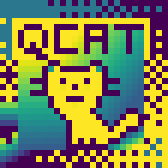
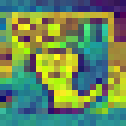

In [3]:
job = client.jobs.run(
    engine=ENGINE,
    params={
        "machine": "fake_fez",
        "shots": 4096,
        "range_correction": False,
    },
    files={
        "image": "qcat28_color.png",
    },
)
row({"input": big("qcat28_color.png"), "fake_fez": big(job.output_bytes())})

## Parameters

What to expect from each:

- `machine`: `aer` is a noiseless simulator; `fake_<chip>` (e.g. `fake_fez`, `fake_torino`) emulates that IBM chip's calibrated noise; `ibm_<chip>` and `least_busy` run on real hardware (your account needs QPU access).
- `shots`: measurements per processed field. More shots, truer values; on `aer` they're the only source of error.
- `range_correction`: noise pulls decoded values towards the middle. Turn this on to stretch each field back over its original range.
- `distortion` and `gate_pauli` (real hardware only): a two-qubit gate $e^{i\alpha/2\, P\otimes Q}$ between neighbouring data qubits, with $\alpha$ = `distortion` and $(P, Q)$ = `gate_pauli` (default `XZ`). On simulators and emulated chips the readout drops this gate, so the engine refuses `distortion` above 0 unless `machine` is a real chip (`ibm_<chip>` or `least_busy`).
- `separate_rgb`: on (default), each colour coordinate gets its own circuit. Off, the sphere's two angles share one qubit, one in the rotation and one in the phase: half the circuits, more noise.
- `fixed_palette`: encode each pixel's index in the image's own palette (up to 256 colours) instead of its sphere coordinates. Best for flat, graphic images.

In [4]:
# client.engines.get(ENGINE)  # its description, params, input and output files, from the API

## How it works

**Colour to sphere.** Each colour maps to a point on a sphere: 50% grey at the centre, white at the top pole, black at the bottom, the most vivid colours around the equator, and hue as the angle around it. A colour is then a radius and two angles, the coordinates that describe a qubit state $\cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$.

**Data and address qubits.** The chip's coupling graph is 2-coloured into data qubits, which hold values, and address qubits, which act as shared controls. A data qubit with $m$ address neighbours stores $2^m$ values, one per setting of its address register, so a chip's capacity is $\sum 2^{\deg}$ over its data qubits (448 values on IBM Fez).

**Run and decode.** Each field is encoded as rotations (on real hardware, optionally distorted by the two-qubit gate), then measured `shots` times in the bases that read it back. Decoding turns the counts back into angles, angles into colours.

**Noise.** On an emulated or real chip, readout errors and decoherence pull every value towards the centre of its range: the image greys and flattens, and qubits that misread leave specks. `range_correction` stretches the range back out; it can't undo the specks.

## Experiments

Each experiment changes one parameter and keeps the others fixed, and runs one job per value.

### Machine

The noiseless simulator returns QCAT almost exactly; each emulated chip leaves its own pattern of fading and specks.

machine=aer
machine=fake_fez
machine=fake_torino
machine=fake_sherbrooke


input,aer,fake_fez,fake_torino,fake_sherbrooke

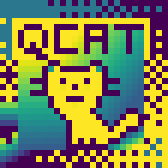
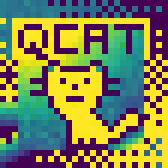
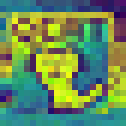
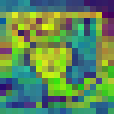
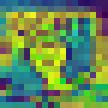

In [5]:
outputs = {"input": big("qcat28_color.png")}
for machine in ("aer", "fake_fez", "fake_torino", "fake_sherbrooke"):
    print(f"machine={machine}")
    job = client.jobs.run(engine=ENGINE, params={"machine": machine}, files={"image": "qcat28_color.png"}, quiet=True)
    outputs[machine] = big(job.output_bytes())
row(outputs)

### Range correction

Same chip, same noise: correction stretches the washed-out decode back to full contrast.

range_correction=False
range_correction=True


input,correction off,correction on

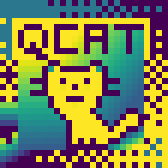
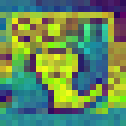
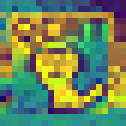

In [6]:
outputs = {"input": big("qcat28_color.png")}
for range_correction in (False, True):
    print(f"range_correction={range_correction}")
    job = client.jobs.run(engine=ENGINE, params={"machine": "fake_fez", "range_correction": range_correction},
                          files={"image": "qcat28_color.png"}, quiet=True)
    outputs[f"correction {'on' if range_correction else 'off'}"] = big(job.output_bytes())
row(outputs)

### Encoding

On `fake_fez`: three circuits per pixel (default), two angles packed on one qubit, or the palette index alone.

separate RGB {}
packed angles {'separate_rgb': False}
palette {'fixed_palette': True}


input,separate RGB,packed angles,palette

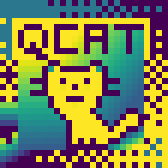
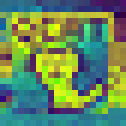
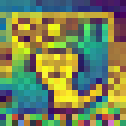
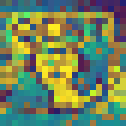

In [5]:
outputs = {"input": big("qcat28_color.png")}
for label, params in [("separate RGB", {}), ("packed angles", {"separate_rgb": False}), ("palette", {"fixed_palette": True})]:
    print(label, params)
    job = client.jobs.run(engine=ENGINE, params={"machine": "fake_fez", **params}, files={"image": "qcat28_color.png"}, quiet=True)
    outputs[label] = big(job.output_bytes())
row(outputs)

### Shots

Greyscale QCAT on the noiseless simulator: with few shots, each pixel's value is estimated from a handful of measurements and grain appears.

shots=128
shots=1024
shots=8192


input,128 shots,1024 shots,8192 shots

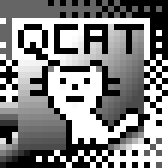
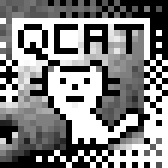
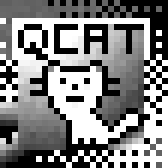
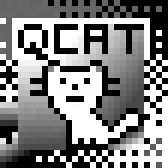

In [6]:
outputs = {"input": big("qcat28.png")}
for shots in (128, 1024, 8192):
    print(f"shots={shots}")
    job = client.jobs.run(engine=ENGINE, params={"machine": "aer", "shots": shots}, files={"image": "qcat28.png"}, quiet=True)
    outputs[f"{shots} shots"] = big(job.output_bytes())
row(outputs)

### Distortion (real hardware)

`distortion` only acts on a real chip: everywhere else the readout drops the gate, and the engine refuses it. Uncomment to run it if your account has QPU access, and expect a queue.

In [ ]:
# outputs = {}
# for distortion in (0.0, 1.0):
#     job = client.jobs.run(engine=ENGINE, params={"machine": "least_busy", "distortion": distortion, "gate_pauli": "XZ"},
#                           files={"image": "qcat28_color.png"})
#     outputs[f"distortion {distortion}"] = big(job.output_bytes())
# row(outputs)

## Questions

**Is this running on quantum hardware?**

On `aer` and `fake_<chip>`, no: those are simulators, the second with a real chip's measured noise. `ibm_<chip>` and `least_busy` submit to IBM hardware and need an account with QPU access; queues can take minutes to hours.

**What size of image works?**

Pixel art. Every value needs a slot on the chip (448 on Fez), so small images run in one pass and larger ones need more circuits. Flat images with few colours suit `fixed_palette`.

**Why does the image go grey on a noisy chip?**

Noise pushes measured values towards the middle of the range, which on the colour sphere is grey. `range_correction` stretches the result back.

**Where can I read more?**

The Tessa paper and its `tessa` library (by Daniel Bultrini) describe the encoding, the device graphs and the hardware runs.

QCAT pixel art by Daniel Bultrini.